<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%22%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris(as_frame=True)
features_iris = iris.data.copy()
display(features_iris.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

In [ ]:
X_iris = StandardScaler().fit_transform(features_iris)

print(features_iris.shape)
print(X_iris.mean(axis=0).round(2))

(150, 4)
[-0. -0. -0. -0.]


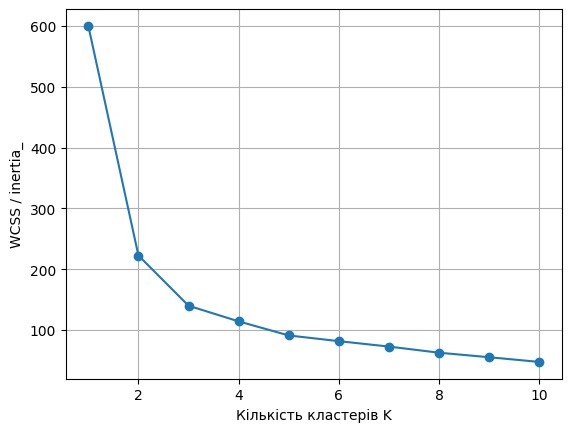

In [17]:
ks = range(1, 11)
inertias = []
for k in ks:
  model = KMeans(n_clusters=k, random_state=42, n_init=10)
  model.fit(X_iris)
  inertias.append(model.inertia_)
plt.plot(list(ks), inertias, marker='o')
plt.xlabel('Кількість кластерів K')
plt.ylabel('WCSS / inertia_')
plt.grid(True); plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

Найвищий середній силует: 2
Показники: {2: np.float64(0.582), 3: np.float64(0.46), 4: np.float64(0.387), 5: np.float64(0.346), 6: np.float64(0.317), 7: np.float64(0.32), 8: np.float64(0.339), 9: np.float64(0.342), 10: np.float64(0.352)}


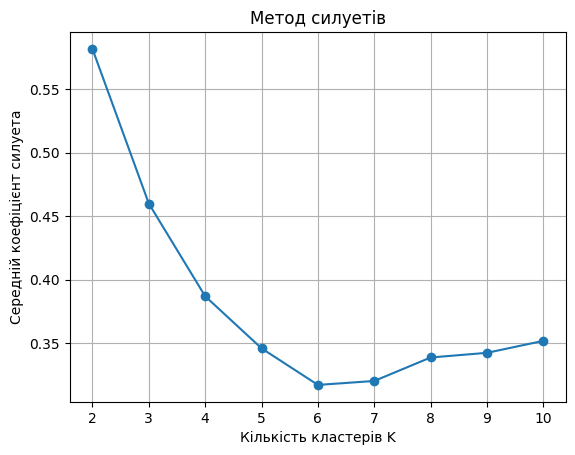

In [19]:
scores = {}
for k in range(2,11):
  labels = KMeans(n_clusters=k, n_init=10,
    random_state=42).fit_predict(X_iris)
  scores[k] = silhouette_score(X_iris, labels)

best_k = max(scores, key=scores.get)
print('Найвищий середній силует:', best_k)
print('Показники:', {k: round(v, 3) for k, v in scores.items()})

plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

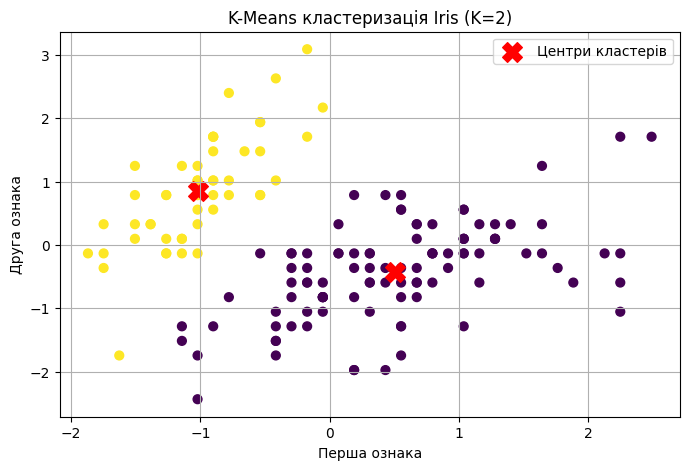

In [15]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_iris)

centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 5))

plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=labels,
    cmap='viridis',
    s=40
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=200,
    c='red',
    label='Центри кластерів'
)

plt.xlabel('Перша ознака')
plt.ylabel('Друга ознака')
plt.title('K-Means кластеризація Iris (K=2)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.
За методом ліктя оптимальною кількістю кластерів було визначено 3, оскільки саме з третього кластера WCSS зменшується поступово після різкого спаду. За методом силуетів найвище значення середнього коефіцієнта (приблизно 0,58) отримано при 2 кластерах. Тому для фінальної кластеризації було обрано 2 кластери, оскільки цей варіант забезпечує краще розділення та компактність кластерів за показником Silhouette Score. Отже, результати методів не повністю збігаються, але вибір двох кластерів підтверджується графіком методу силуетів.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [33]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [34]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [35]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [37]:
df.isna().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [38]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [39]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [40]:
X = df.drop(columns=["GradeClass","StudentID"])
y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

students_scaler = StandardScaler()

X_train_scaled = students_scaler.fit_transform(X_train)
X_test_scaled = students_scaler.transform(X_test)

Train: (1913, 13)
Test: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [43]:
cv = 5

search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 2, 4]
    },
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

search.fit(X_train, y_train)

print('Найкращі гіперпараметри:', search.best_params_)
print('CV accuracy:', round(search.best_score_, 3))
print('Test accuracy:', round(
    accuracy_score(y_test, search.predict(X_test)), 3
))

Найкращі гіперпараметри: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
CV accuracy: 0.921
Test accuracy: 0.91


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [44]:
cv = 5

search_lr = GridSearchCV(
    LogisticRegression(
        solver='saga',
        max_iter=5000,
        random_state=42
    ),
    {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2']
    },
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

search_lr.fit(X_train_scaled, y_train)

print('Найкращі гіперпараметри:', search_lr.best_params_)
print('CV accuracy:', round(search_lr.best_score_, 3))
print('Test accuracy:', round(
    accuracy_score(y_test, search_lr.predict(X_test_scaled)), 3
))

Найкращі гіперпараметри: {'C': 0.1, 'penalty': 'l1'}
CV accuracy: 0.802
Test accuracy: 0.818


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [45]:
cv = 5

search_svm = GridSearchCV(
    SVC(),
    {
        'C': [0.1, 1, 10, 100],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    },
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

search_svm.fit(X_train_scaled, y_train)

print('Найкращі гіперпараметри:', search_svm.best_params_)
print('CV accuracy:', round(search_svm.best_score_, 3))
print('Test accuracy:', round(
    accuracy_score(y_test, search_svm.predict(X_test_scaled)), 3
))

Найкращі гіперпараметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
CV accuracy: 0.855
Test accuracy: 0.85


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [46]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [
        search.best_score_,
        search_lr.best_score_,
        search_svm.best_score_
    ],
    'Test accuracy': [
        accuracy_score(y_test, search.predict(X_test)),
        accuracy_score(y_test, search_lr.predict(X_test_scaled)),
        accuracy_score(y_test, search_svm.predict(X_test_scaled))
    ]
})

print(results)

                Модель  CV accuracy  Test accuracy
0        Random Forest     0.920549       0.910230
1  Logistic Regression     0.802411       0.818372
2                  SVM     0.854677       0.849687


### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

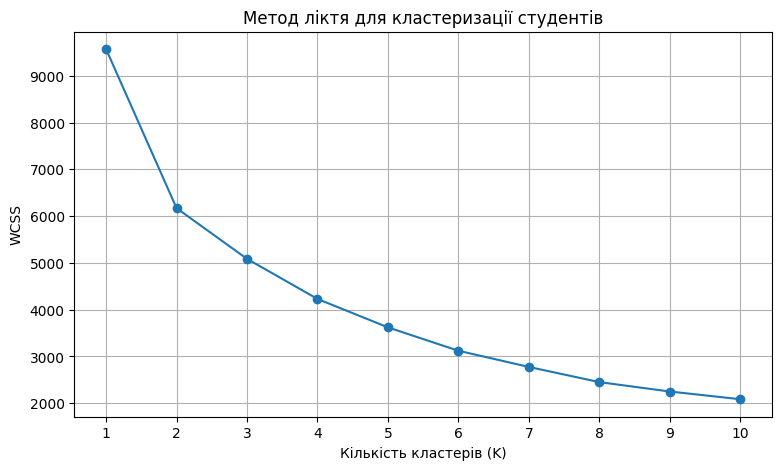

In [47]:
X = df[['Age', 'StudyTimeWeekly', 'Absences', 'GPA']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Метод ліктя для кластеризації студентів')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

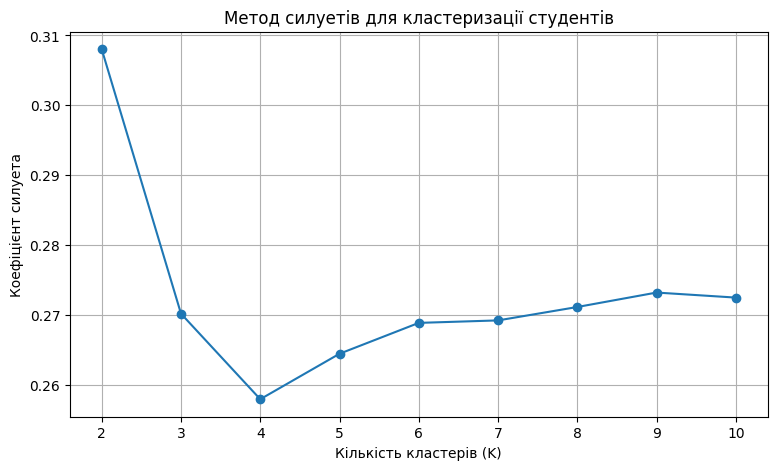

In [49]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Побудова графіка
plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.title('Метод силуетів для кластеризації студентів')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('Коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [50]:
%pip install kneed
%pip install yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [51]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [53]:
X_pca = df.drop(columns=['StudentID', 'GradeClass'])

display(X_pca.head())

,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196
1,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915
2,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602
3,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218
4,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [54]:
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)
pca = PCA()
X_pca_transformed = pca.fit_transform(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance):
    print(f"PC{i + 1}: {variance:.4f} ({variance * 100:.2f}%)")
print("Сумарна пояснена дисперсія:",
      pca.explained_variance_ratio_.sum())

PC1: 0.1525 (15.25%)
PC2: 0.0861 (8.61%)
PC3: 0.0827 (8.27%)
PC4: 0.0807 (8.07%)
PC5: 0.0786 (7.86%)
PC6: 0.0779 (7.79%)
PC7: 0.0763 (7.63%)
PC8: 0.0760 (7.60%)
PC9: 0.0744 (7.44%)
PC10: 0.0738 (7.38%)
PC11: 0.0717 (7.17%)
PC12: 0.0675 (6.75%)
PC13: 0.0018 (0.18%)
Сумарна пояснена дисперсія: 0.9999999999999999


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [55]:
components = range(1, len(explained_variance) + 1)

knee = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

print("Оптимальна кількість компонент:", knee.elbow)

Оптимальна кількість компонент: 2


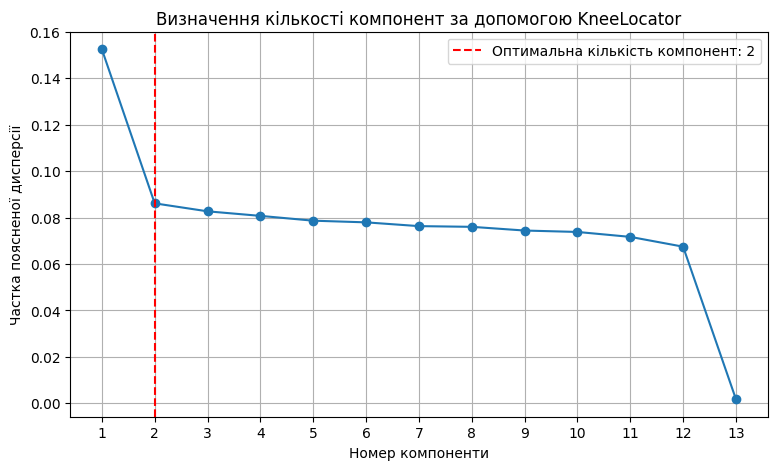

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(components, explained_variance, marker='o')

if knee.elbow is not None:
    plt.axvline(
        x=knee.elbow,
        color='red',
        linestyle='--',
        label=f'Оптимальна кількість компонент: {knee.elbow}'
    )

plt.title('Визначення кількості компонент за допомогою KneeLocator')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(list(components))
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.